In [76]:

# What is Machine Learning?

# It is a method where machine learns patterns from the data instead of being explicitly programmed.
# Major Uses:
# 1. Automation of decision
# 2. Handling of complex patterns
# 3. Improving accuracy of system over time
# 4. Used in finance, healthcare, marketing, self-driving, recommendation systems.


# Traditional Programming vs Machine Learnings
# Traditional Programming: Rules -> Output
# Machine Learning: Data -> Model -> Output


In [77]:

# Types of Machine Learning:
# 1. Supervised Learning
#     a. Input + Output
#     b. Predict Labels or Predict Values
#     c. Example: Linear Regression, House Price Detection, Spam Detection, Decision Tree

# 2. Unsupervised Learning
#     a. No output labels
#     b. Finds hidden patterns
#     c. Example: KNN (K neighbors classification), PCA (Principal Component Analysis), Clustering

# 3. Reinforcement Learning
#     a. Agent learns by interacting with environment
#     b. Rewards & Penalties
#     c. Used in robotics, games, navigation


In [78]:

# Machine Learning Workflow

# 1. Problem Definition
# 2. Data Collection
# 3. Data Cleaning
# 4. Feature Engineering
# 5. Model Training
# 6. Evaluation
# 7. Deployment
# 8. Monitoring

In [79]:
#Problem (Predict ticket fare for a given age.)

In [80]:
#Data Collection
import pandas as pd

df=pd.read_csv('data/Titanic-Dataset.csv')

df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [82]:
df.loc[df['Age'].isna(),'Age']=df['Age'].median()


In [83]:
df.drop(columns=['Cabin'],inplace=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(4)
memory usage: 76.7 KB


C:\Users\saura\AppData\Local\Temp\ipykernel_19072\4004405979.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Cabin'],inplace=True)


In [84]:
df.loc[df['Embarked'].isna(),'Embarked']=df['Embarked'].mode()[0]

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    str    
dtypes: float64(2), int64(5), str(4)
memory usage: 76.7 KB


In [85]:
df['Fare'].describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

(array([732., 106.,  31.,   2.,  11.,   6.,   0.,   0.,   0.,   3.]),
 array([  0.     ,  51.23292, 102.46584, 153.69876, 204.93168, 256.1646 ,
        307.39752, 358.63044, 409.86336, 461.09628, 512.3292 ]),
 <BarContainer object of 10 artists>)

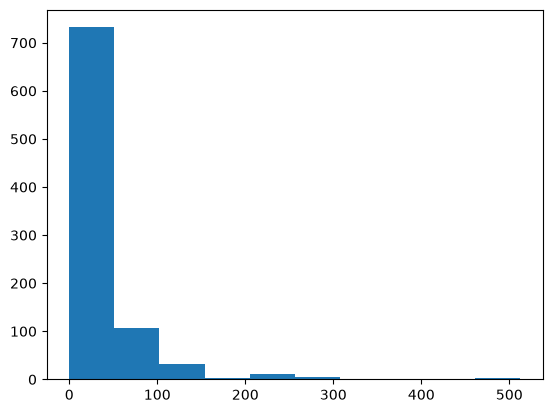

In [86]:
import matplotlib.pyplot as plt

plt.hist(df['Fare'])

In [87]:
df[df['Fare']>124].count()


PassengerId    38
Survived       38
Pclass         38
Name           38
Sex            38
Age            38
SibSp          38
Parch          38
Ticket         38
Fare           38
Embarked       38
dtype: int64

In [88]:

#IQR

q1=df['Fare'].quantile(0.25) #First Quartile
q3=df['Fare'].quantile(0.75) #Third Quartile

iqr=q3-q1

# Upper bound, lower bound ==> data that exists outside of these are outliers 
upper_bound=q3+3*q3
lower_bound=q1-1.5*q1

outliers=df[df['Fare']>124]
outliers

rows_to_drop_index=df.loc[(df['Fare']>upper_bound) & (df['Fare']>lower_bound) ].index.to_list()
df_final=df
df_final.drop(rows_to_drop_index,inplace=True)


C:\Users\saura\AppData\Local\Temp\ipykernel_19072\1118629977.py:17: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_final.drop(rows_to_drop_index,inplace=True)


In [89]:
#Linear Regression (y=mx+c) m-->coefficient, c-->intercept

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split

X=df_final[['Age']] #Feature Column
Y=df_final['Fare'] #Prediction Column

#When creating a machine learning model, we split data into training_data and testing_data
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2)

model=LinearRegression()
model.fit(X_train,Y_train)

# model.coef_ --> coefficient (m)
# model.intercept_ -->  intercept (c)



,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.2]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Age']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,17.93
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [90]:
model.intercept_
model.coef_

array([0.2037796])

In [91]:
y_prediction=model.predict(X_test)


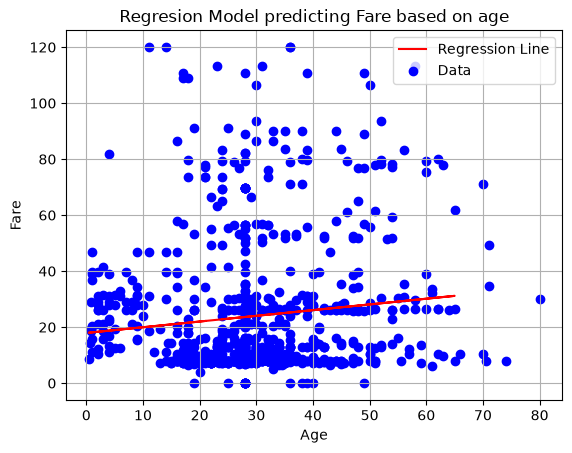

In [92]:
import matplotlib.pyplot as plt

plt.plot(X_test['Age'],y_prediction,label='Regression Line',color='Red')
plt.scatter(X['Age'],Y,label='Data',color="Blue")
plt.xlabel("Age")
plt.ylabel("Fare")
plt.title("Regresion Model predicting Fare based on age")
plt.grid(True)
plt.legend()

In [93]:
import numpy as np


value=np.array([34,45,23,67]).reshape(-1,1)

prediction_value=model.predict(value)

prediction_value

c:\Users\saura\Documents\Python\python_55_days_programs\machine_learning\venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([24.85549634, 27.09707197, 22.61392071, 31.58022323])

In [94]:
from sklearn.metrics import mean_squared_error,r2_score

mse=mean_squared_error(y_prediction,Y_test)
mse

r2_score=r2_score(y_prediction,Y_test)
r2_score


-91.62673682447456